# 17. Study with the classical benchmark series

**Goal and requirements.** Compare standalone and hybrid models on 17 classical Rdatasets series, split into three classes (stationary, higher and lower seasonal strength): five models, among them the ARIMA–ANN hybrid, evaluated in protocols A (12 steps at once) and B (one step at a time), with 3, 6 and 12 lags, error by class, curves by horizon, the hybrid × base contrast and cost. There is no search and no champion: each model is fitted once on the history before the test and evaluated once on the test. `stats` and `plot` extras; downloads the series on the first run.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.data.characterization import characterize
from autohybts.datasets import raw_dataset
from autohybts.domain.specs import CandidateSpec, ModelSpec
from autohybts.reporting.comparison import holm

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc3


## 1. Data and protocol

Study rules: a 12-point test (error summarized at horizons 1, 3, 6 and 12), at least 60 observations and no relative jump above 100 % before the test. Each series gets a synthetic daily index (the original frequency does not enter the models); the models' seasonal period is 12.

In [2]:
CATALOG = {
    "air_passengers": "AirPassengers",
    "australian_residents": "austres",
    "bj_sales": "BJsales",
    "us_accidental_deaths": "USAccDeaths",
    "discoveries": "discoveries",
    "johnson_johnson": "JohnsonJohnson",
    "lake_huron": "LakeHuron",
    "female_lung_deaths": "fdeaths",
    "lynx": "lynx",
    "nile": "Nile",
    "nottingham_temperature": "nottem",
    "northern_hemisphere_temperature": "nhtemp",
    "sunspot_year": "sunspot.year",
    "monthly_sunspots": "sunspots",
    "tree_ring": "treering",
    "uk_driver_deaths": "UKDriverDeaths",
    "web_usage": "WWWusage",
}
H = 12
HORIZONS = [1, 3, 6, 12]


def max_relative_jump(values):
    level = np.maximum(np.abs(values[1:]), np.abs(values[:-1]))
    jumps = np.divide(
        np.abs(np.diff(values)), level, out=np.zeros(len(values) - 1), where=level > 0
    )
    return float(jumps.max())


series = {}
for sid, name in CATALOG.items():
    values = raw_dataset("rdatasets", package="datasets", name=name)["value"].to_numpy(float)
    series[sid] = pd.Series(
        values, index=pd.date_range("2000-01-01", periods=len(values), freq="D"), name=sid
    )
series = {
    sid: y
    for sid, y in series.items()
    if len(y) >= 60 and max_relative_jump(y.to_numpy()[:-H]) <= 1.0
}
print("eligible series:", len(series))

eligible series: 17


## 2. Causal exploration

Two rules on the stretch before the test: ADF decides whether the series is stationary; for the others, the strength of a robust STL on the Box-Cox series (periods 4 and 12) separates higher seasonal strength (above 0.5) from lower. Every eligible series enters the study.

In [3]:
selection = pd.DataFrame(
    {sid: characterize(y.to_numpy()[:-H], (4, 12)) for sid, y in series.items()}
).T
selection = selection[
    ["n", "adf_stat_d0", "adf_pvalue_d0", "diff_order", "fs_4", "fs_12", "fs", "category"]
]
CAT = {
    "stationary": "Stationary",
    "seasonal": "Higher seasonal strength",
    "nonseasonal": "Lower seasonal strength",
}
selection.sort_values(["category", "fs"])

,n,adf_stat_d0,adf_pvalue_d0,diff_order,fs_4,fs_12,fs,category
australian_residents,77,2.219085,0.998898,2,0.0,0.0,0.0,nonseasonal
bj_sales,138,-1.091853,0.71831,1,0.0,0.0,0.0,nonseasonal
lake_huron,86,-2.837671,0.053091,1,0.189103,0.26618,0.26618,nonseasonal
lynx,102,-2.710587,0.072224,1,0.026964,0.275202,0.275202,nonseasonal
web_usage,88,-2.842188,0.052496,2,0.005612,0.282459,0.282459,nonseasonal
northern_hemisphere_temperature,48,-2.704231,0.073309,1,0.262481,0.381753,0.381753,nonseasonal
uk_driver_deaths,180,-0.063104,0.952992,1,-0.032983,0.765658,0.765658,seasonal
johnson_johnson,72,3.515816,1.0,2,0.837438,0.705074,0.837438,seasonal
air_passengers,132,0.888027,0.992932,2,-0.17221,0.957727,0.957727,seasonal
us_accidental_deaths,60,-4.715744,0.000079,0,NaN,NaN,NaN,stationary


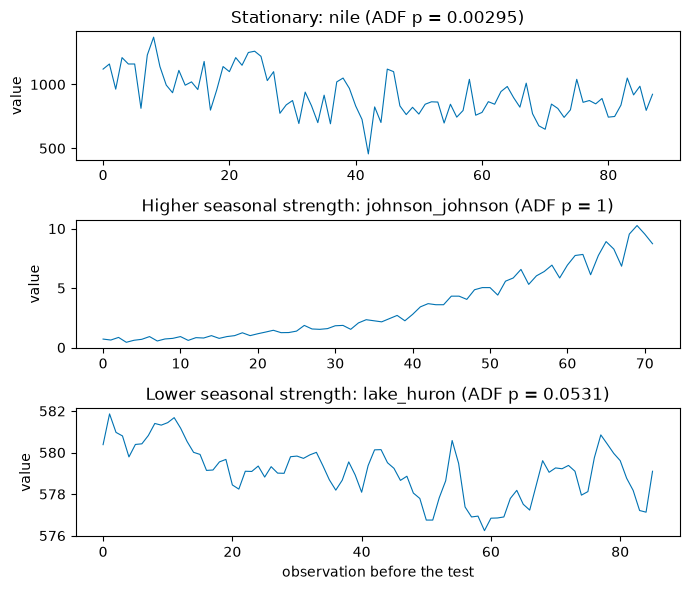

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(7, 6))
for ax, (category, title) in zip(axes, CAT.items(), strict=True):
    group = selection[selection.category == category].sort_values("fs", na_position="first")
    sid = group.index[(len(group) - 1) // 2]
    ax.plot(series[sid].to_numpy()[:-H], color="#0072B2", linewidth=0.8)
    ax.set(
        title=f"{title}: {sid} (ADF p = {selection.loc[sid, 'adf_pvalue_d0']:.3g})", ylabel="value"
    )
axes[-1].set_xlabel("observation before the test")
fig.tight_layout()
plt.show()

## 3. Controls and proposed models

Five models: persistence as the control; ETS and ARIMA, without lags; KNN with 3, 6 and 12 lags; and the ARIMA–ANN hybrid, in which an MLP corrector (5 neurons, logistic activation, lbfgs) forecasts the ARIMA error from windows of 3, 6 and 12 out-of-sample residuals. Each configuration is identified by model and number of lags (`knn_6`, `arima_ann_12`); the hybrid is compared with its base, ARIMA.

In [5]:
LAGS = [3, 6, 12]
FIXED = {
    "naive": ("naive", {}, "statistical"),
    "ets": ("exponential_smoothing", {"season_length": 12}, "statistical"),
    "arima": ("arima", {}, "statistical"),
}
LAGGED = {"knn": "kernel"}
PAIRS = [("arima_ann", "arima")]
ANN = {
    "random_state": 42,
    "estimator_params": {
        "hidden_layer_sizes": [5],
        "activation": "logistic",
        "solver": "lbfgs",
        "max_iter": 2000,
    },
}


def specs(variant):
    """(structure, lags) -> specification; lags = 0 for the models without lags."""
    out = {
        (structure, 0): CandidateSpec.standalone(name, params, family=family, variant=variant)
        for structure, (name, params, family) in FIXED.items()
    }
    for lags in LAGS:
        for structure, family in LAGGED.items():
            out[structure, lags] = CandidateSpec.standalone(
                structure, {"lags": lags}, family=family, variant=variant
            )
        for hybrid, base in PAIRS:
            name, params, _ = FIXED[base]
            out[hybrid, lags] = CandidateSpec(
                "residual",
                "residual_additive",
                ModelSpec.of(name, params),
                ModelSpec.of("mlp", ANN),
                lags,
                1.0,
                "historical_oof_1step",
                variant=variant,
            )
    return out


print(len(specs("A")), "models per protocol")

9 models per protocol


## 4. Fitting and evaluation

For each series and protocol, an experiment seals the last 12 points. Each model is refitted on the earlier history and read a single time on the test: in A, the 12 steps come at once; in B, they are 12 one-step forecasts, each value revealed after its forecast and without refitting. The error is the RRMSE accumulated up to each horizon. Failures are recorded and do not stop the study.

In [6]:
def cumulative_rrmse(y_true, y_pred):
    h = np.arange(1, len(y_true) + 1)
    rmse = np.sqrt(np.cumsum((y_true - y_pred) ** 2) / h)
    return rmse / (np.cumsum(y_true) / h)


rows, failures = [], []
for sid, y in series.items():
    for protocol in ("A", "B"):
        exp = AutoHybridExperiment(
            fh=H if protocol == "A" else 1,
            test_size=H,
            variant=protocol,
            seasonal_period=12,
            metrics=["RRMSE", "MASE"],
            session_id=42,
        ).fit(y)
        for (structure, lags), spec in specs(protocol).items():
            started = time.perf_counter()
            try:
                predictions = exp.evaluate_external(exp.finalize_model(spec)).predictions
            except Exception as error:
                failures.append(
                    {
                        "series_id": sid,
                        "protocol": protocol,
                        "structure": structure,
                        "lags": lags,
                        "error": str(error)[:120],
                    }
                )
                continue
            seconds = time.perf_counter() - started
            curve = cumulative_rrmse(
                predictions["y_true"].to_numpy(), predictions["y_pred"].to_numpy()
            )
            model = structure if lags == 0 else f"{structure}_{lags}"
            rows += [
                {
                    "series_id": sid,
                    "protocol": protocol,
                    "structure": structure,
                    "lags": lags,
                    "model": model,
                    "h": h,
                    "rrmse": value,
                    "seconds": seconds,
                }
                for h, value in enumerate(curve, start=1)
            ]
metrics = pd.DataFrame(rows).merge(selection[["category"]], left_on="series_id", right_index=True)
final = metrics[metrics.h == H]
print(final.series_id.nunique(), "series |", len(final), "evaluations |", len(failures), "failures")
pd.DataFrame(failures)

17 series | 306 evaluations | 0 failures


""


## 5. Results and plots

Mean RRMSE of each model at `h = 12`, by protocol and class (the series are the unit of analysis), and the three best of each group.

In [7]:
final.pivot_table(index="model", columns=["protocol", "category"], values="rrmse").sort_values(
    ("A", "stationary")
).round(4)

protocol               A                               B                    
category     nonseasonal seasonal stationary nonseasonal seasonal stationary
model                                                                       
knn_12            0.0956   0.2249     0.3628      0.0932   0.2221     0.3033
knn_6             0.0876   0.3172     0.3750      0.0972   0.2408     0.2990
arima             0.1349   0.1719     0.4304      0.0470   0.1346     0.2931
ets               0.1390   0.1184     0.4626      0.0690   0.0783     0.2811
knn_3             0.0959   0.2561     0.4665      0.0887   0.2180     0.2931
arima_ann_12      0.1935   0.2169     0.5187      0.1474   0.1834     0.3990
arima_ann_6       0.2038   0.2617     0.5875      0.1851   0.2058     0.5188
naive             0.2034   0.2562     0.6212      0.0880   0.1578     0.3342
arima_ann_3       0.2080   0.2497     0.6395      0.1302   0.2419     0.5315

In [8]:
(
    final.groupby(["protocol", "category", "model"], as_index=False)
    .rrmse.mean()
    .sort_values("rrmse")
    .groupby(["protocol", "category"])
    .head(3)
    .sort_values(["protocol", "category", "rrmse"])
)

,protocol,category,model,rrmse
7,A,nonseasonal,knn_6,0.087648
5,A,nonseasonal,knn_12,0.095574
6,A,nonseasonal,knn_3,0.095880
13,A,seasonal,ets,0.118422
9,A,seasonal,arima,0.171893
10,A,seasonal,arima_ann_12,0.216868
23,A,stationary,knn_12,0.362759
25,A,stationary,knn_6,0.375010
18,A,stationary,arima,0.430371
27,B,nonseasonal,arima,0.047023


Mean accumulated RRMSE at horizons 1, 3, 6 and 12, by protocol and class.

In [9]:
metrics[metrics.h.isin(HORIZONS)].pivot_table(
    index="model", columns=["protocol", "category", "h"], values="rrmse"
).sort_values(("A", "stationary", H)).round(3)

protocol               A                                                     \
category     nonseasonal                      seasonal                        
h                     1      3      6      12       1      3      6      12   
model                                                                         
knn_12             0.046  0.076  0.087  0.096    0.215  0.220  0.229  0.225   
knn_6              0.028  0.075  0.082  0.088    0.199  0.246  0.318  0.317   
arima              0.009  0.074  0.097  0.135    0.070  0.147  0.159  0.172   
ets                0.102  0.129  0.137  0.139    0.096  0.114  0.116  0.118   
knn_3              0.012  0.063  0.068  0.096    0.117  0.190  0.226  0.256   
arima_ann_12       0.098  0.154  0.194  0.194    0.046  0.184  0.238  0.217   
arima_ann_6        0.057  0.093  0.185  0.204    0.040  0.253  0.248  0.262   
naive              0.114  0.172  0.188  0.203    0.136  0.170  0.228  0.256   
arima_ann_3        0.061  0.150  0.163  0.208    0.036  0.160  0.245  0.250   

protocol                        ...           B                                \
category     stationary         ... nonseasonal        seasonal                 
h                    1      3   ...          6      12       1      3      6    
model                           ...                                             
knn_12            0.131  0.288  ...       0.053  0.093    0.215  0.202  0.217   
knn_6             0.127  0.301  ...       0.088  0.097    0.199  0.228  0.226   
arima             0.169  0.324  ...       0.047  0.047    0.070  0.104  0.123   
ets               0.174  0.343  ...       0.075  0.069    0.096  0.089  0.082   
knn_3             0.118  0.265  ...       0.085  0.089    0.117  0.194  0.188   
arima_ann_12      0.232  0.397  ...       0.172  0.147    0.046  0.154  0.213   
arima_ann_6       0.471  0.465  ...       0.123  0.185    0.040  0.182  0.157   
naive             0.192  0.407  ...       0.098  0.088    0.136  0.111  0.148   
arima_ann_3       0.195  0.461  ...       0.086  0.130    0.036  0.136  0.130   

protocol                                             
category            stationary                       
h                12         1      3      6      12  
model                                                
knn_12        0.222      0.131  0.244  0.239  0.303  
knn_6         0.241      0.127  0.242  0.233  0.299  
arima         0.135      0.169  0.245  0.235  0.293  
ets           0.078      0.174  0.221  0.216  0.281  
knn_3         0.218      0.118  0.190  0.216  0.293  
arima_ann_12  0.183      0.232  0.302  0.266  0.399  
arima_ann_6   0.206      0.471  0.391  0.419  0.519  
naive         0.158      0.192  0.294  0.310  0.334  
arima_ann_3   0.242      0.195  0.331  0.357  0.532  

[9 rows x 24 columns]

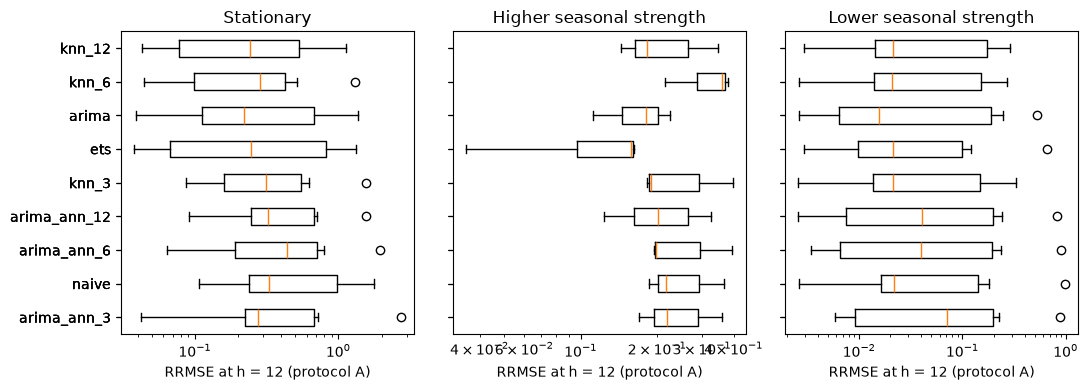

In [10]:
order = final[final.protocol == "A"].groupby("model").rrmse.mean().sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
for ax, (category, title) in zip(axes, CAT.items(), strict=True):
    data = final[(final.protocol == "A") & (final.category == category)]
    ax.boxplot(
        [data.loc[data.model == m, "rrmse"] for m in order], vert=False, tick_labels=list(order)
    )
    ax.set(title=title, xlabel="RRMSE at h = 12 (protocol A)", xscale="log")
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

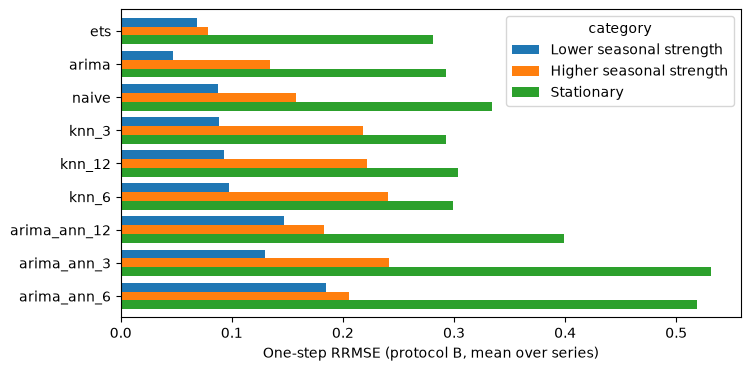

In [11]:
table_b = (
    final[final.protocol == "B"]
    .pivot_table(index="model", columns="category", values="rrmse")
    .rename(columns=CAT)
)
ax = table_b.loc[table_b.mean(axis=1).sort_values().index].plot.barh(figsize=(8, 4), width=0.8)
ax.set(xlabel="One-step RRMSE (protocol B, mean over series)", ylabel="")
ax.invert_yaxis()
plt.show()

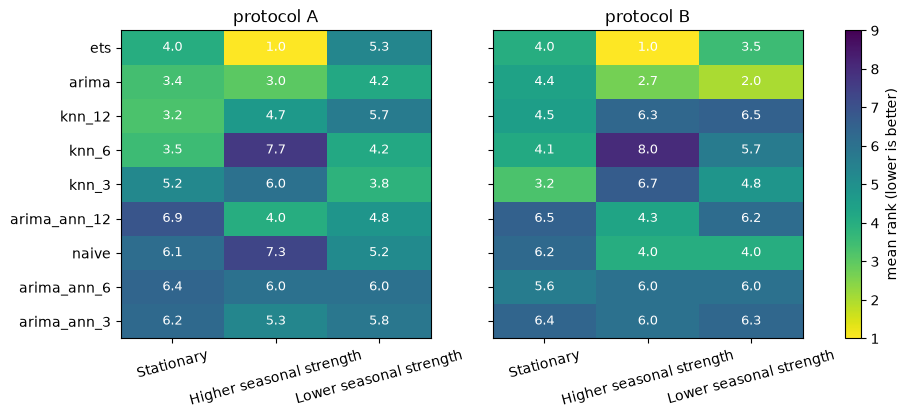

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
order = final.groupby("model").rrmse.mean().sort_values().index
for ax, protocol in zip(axes, ("A", "B"), strict=True):
    part = final[final.protocol == protocol]
    ranks = part.assign(rank=part.groupby("series_id").rrmse.rank())
    table = ranks.pivot_table(index="model", columns="category", values="rank").rename(columns=CAT)
    table = table.loc[order, list(CAT.values())]
    image = ax.imshow(table.to_numpy(), cmap="viridis_r", aspect="auto", vmin=1, vmax=len(order))
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=15)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_title(f"protocol {protocol}")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(
                j, i, f"{table.iloc[i, j]:.1f}", ha="center", va="center", color="white", fontsize=9
            )
fig.colorbar(image, ax=axes, label="mean rank (lower is better)")
plt.show()

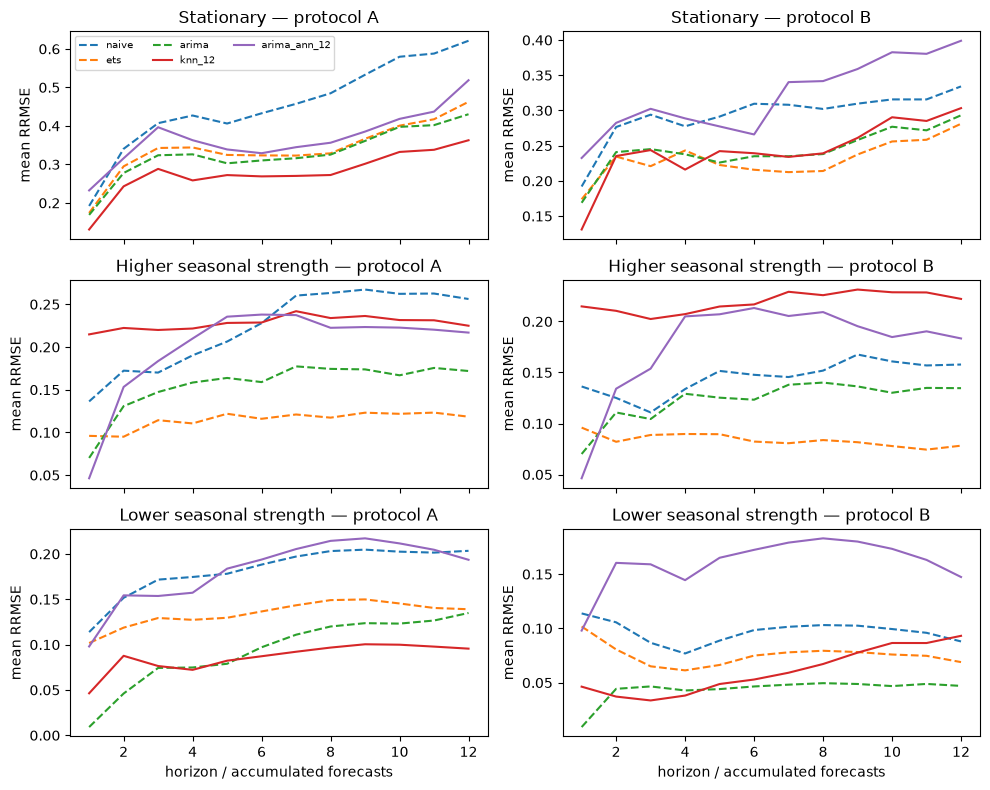

In [13]:
REFERENCE = ["naive", "ets", "arima", "knn_12", "arima_ann_12"]
curves = (
    metrics[metrics.model.isin(REFERENCE)]
    .groupby(["protocol", "category", "model", "h"])
    .rrmse.mean()
)
fig, axes = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
for row, (category, title) in enumerate(CAT.items()):
    for col, protocol in enumerate(("A", "B")):
        ax = axes[row, col]
        for model in REFERENCE:
            values = curves.loc[(protocol, category, model)]
            ax.plot(values.index, values, linestyle="--" if model in FIXED else "-", label=model)
        ax.set(title=f"{title} — protocol {protocol}", ylabel="mean RRMSE")
axes[0, 0].legend(ncol=3, fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("horizon / accumulated forecasts")
fig.tight_layout()
plt.show()

### Effect of the number of lags

Mean RRMSE at `h = 12` of the lag models and of the hybrids with 3, 6 and 12 lags, by class and protocol. The dashed line is persistence, the reference of each panel.

In [14]:
lagged = final[final.lags > 0]
lagged.pivot_table(
    index="structure", columns=["protocol", "category", "lags"], values="rrmse"
).round(4)

protocol            A                                                      \
category  nonseasonal                 seasonal                 stationary   
lags               3       6       12       3       6       12         3    
structure                                                                   
arima_ann      0.2080  0.2038  0.1935   0.2497  0.2617  0.2169     0.6395   
knn            0.0959  0.0876  0.0956   0.2561  0.3172  0.2249     0.4665   

protocol                            B                                   \
category                  nonseasonal                 seasonal           
lags           6       12          3       6       12       3       6    
structure                                                                
arima_ann  0.5875  0.5187      0.1302  0.1851  0.1474   0.2419  0.2058   
knn        0.3750  0.3628      0.0887  0.0972  0.0932   0.2180  0.2408   

protocol                                      
category          stationary                  
lags           12         3       6       12  
structure                                     
arima_ann  0.1834     0.5315  0.5188  0.3990  
knn        0.2221     0.2931  0.2990  0.3033

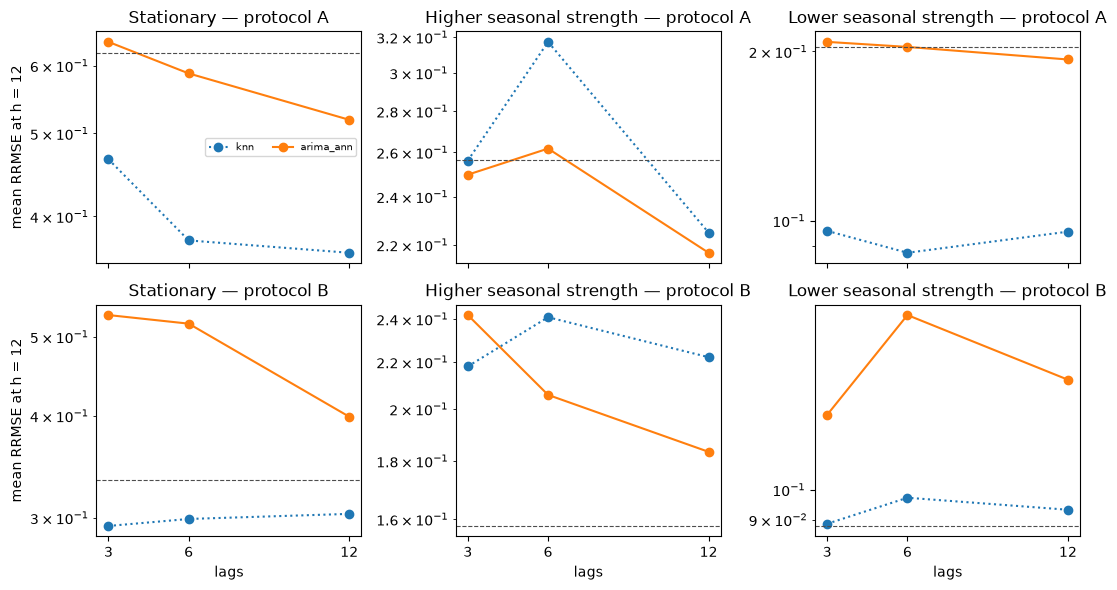

In [15]:
by_lag = lagged.groupby(["protocol", "category", "structure", "lags"]).rrmse.mean()
naive = final[final.model == "naive"].groupby(["protocol", "category"]).rrmse.mean()
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for row, protocol in enumerate(("A", "B")):
    for col, (category, title) in enumerate(CAT.items()):
        ax = axes[row, col]
        for structure in [*LAGGED, *(hybrid for hybrid, _ in PAIRS)]:
            values = by_lag.loc[(protocol, category, structure)]
            ax.plot(
                values.index,
                values,
                marker="o",
                linestyle=":" if structure in LAGGED else "-",
                label=structure,
            )
        ax.axhline(naive.loc[(protocol, category)], color="0.3", linestyle="--", linewidth=0.8)
        ax.set(title=f"{title} — protocol {protocol}", xticks=LAGS, yscale="log")
        if col == 0:
            ax.set_ylabel("mean RRMSE at h = 12")
axes[0, 0].legend(fontsize=7, ncol=2)
for ax in axes[-1]:
    ax.set_xlabel("lags")
fig.tight_layout()
plt.show()

### ARIMA–ANN hybrid against ARIMA

Median gain at `h = 12`, ``100 · (RRMSE_base − RRMSE_hybrid) / RRMSE_base``, by protocol, class and corrector window (positive when the corrector helps), and the RRMSE curves of the base and of the hybrid in each protocol.

In [16]:
wide = metrics.pivot_table(
    index=["series_id", "category", "protocol", "h"], columns="model", values="rrmse"
)
gains = pd.concat(
    (100 * (wide[base] - wide[f"{hybrid}_{lags}"]) / wide[base])
    .rename("gain")
    .reset_index()
    .assign(hybrid=hybrid, lags=lags)
    for hybrid, base in PAIRS
    for lags in LAGS
)
gains[gains.h == H].pivot_table(
    index=["hybrid", "lags"], columns=["protocol", "category"], values="gain", aggfunc="median"
).round(2)

protocol                 A                               B                    
category       nonseasonal seasonal stationary nonseasonal seasonal stationary
hybrid    lags                                                                
arima_ann 3         -37.95   -51.13     -16.50     -126.60   -56.85     -51.62
          6         -20.21   -74.08     -35.59      -82.66   -58.08     -72.30
          12        -24.78   -10.32     -54.96     -118.18    -0.54     -58.42

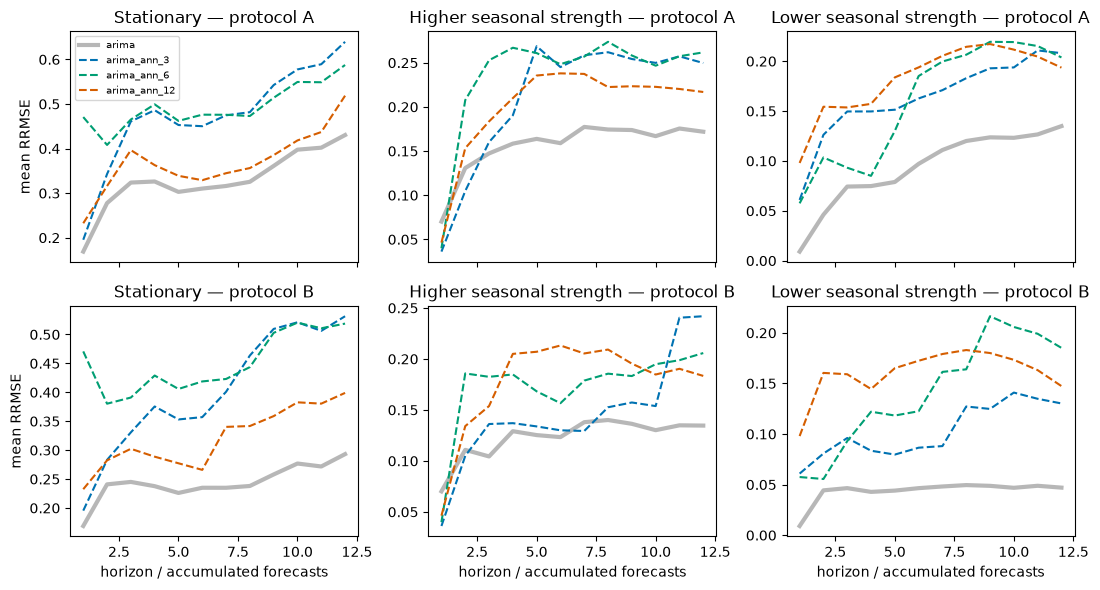

In [17]:
means = metrics.groupby(["model", "category", "protocol", "h"]).rrmse.mean()
hybrid, base = PAIRS[0]
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for row, protocol in enumerate(("A", "B")):
    for col, (category, title) in enumerate(CAT.items()):
        ax = axes[row, col]
        values = means.loc[(base, category, protocol)]
        ax.plot(values.index, values, color="0.3", linewidth=3, alpha=0.4, label=base)
        for lags, color in zip(LAGS, ("#0072B2", "#009E73", "#D55E00"), strict=True):
            values = means.loc[(f"{hybrid}_{lags}", category, protocol)]
            ax.plot(values.index, values, color=color, linestyle="--", label=f"{hybrid}_{lags}")
        ax.set_title(f"{title} — protocol {protocol}")
        if col == 0:
            ax.set_ylabel("mean RRMSE")
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("horizon / accumulated forecasts")
fig.tight_layout()
plt.show()

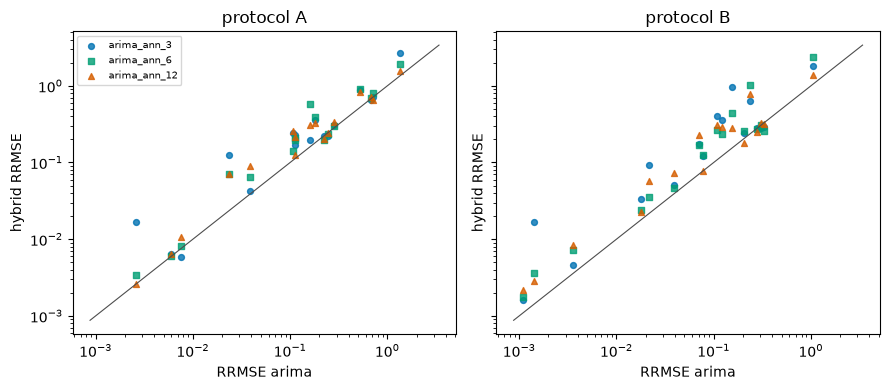

In [18]:
points = final.pivot_table(
    index=["series_id", "category", "protocol"], columns="model", values="rrmse"
).reset_index()
hybrids = [f"{hybrid}_{lags}" for lags in LAGS]
low, high = points[[base, *hybrids]].min().min() * 0.8, points[[base, *hybrids]].max().max() * 1.25
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, protocol in zip(axes, ("A", "B"), strict=True):
    part = points[points.protocol == protocol]
    ax.plot([low, high], [low, high], color="0.3", linewidth=0.8)
    for model, color, marker in zip(
        hybrids, ("#0072B2", "#009E73", "#D55E00"), ("o", "s", "^"), strict=True
    ):
        ax.scatter(
            part[base], part[model], s=18, color=color, marker=marker, alpha=0.8, label=model
        )
    ax.set(
        xscale="log",
        yscale="log",
        title=f"protocol {protocol}",
        xlabel=f"RRMSE {base}",
        ylabel="hybrid RRMSE",
    )
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 6. Diagnostics and limits

Hybrid × base contrasts with the Wilcoxon test paired by series, with Holm's correction within each protocol and class (three contrasts, one per window). With 3 to 8 series per class, the smallest possible p-value is high (with 3 series, 0.25): the tests are for reporting, not for claiming superiority. The corrector window was not chosen on validation: the three are shown side by side. The synthetic daily index ignores the real frequency. Long horizons, such as 365 days, need long series (M4 Daily has series with more than 4000 points); here some series have 60 observations, so the test has 12 steps.

In [19]:
contrasts = []
for (protocol, category), group in final.groupby(["protocol", "category"]):
    table = group.pivot_table(index="series_id", columns="model", values="rrmse")
    rows = []
    for hybrid, base in PAIRS:
        for lags in LAGS:
            paired = table[[f"{hybrid}_{lags}", base]].dropna()
            difference = paired[base] - paired[f"{hybrid}_{lags}"]
            p_value = 1.0 if (difference == 0).all() else float(wilcoxon(difference).pvalue)
            rows.append(
                {
                    "protocol": protocol,
                    "category": category,
                    "hybrid": hybrid,
                    "lags": lags,
                    "n": len(paired),
                    "p_value": p_value,
                    "median_gain_%": float((100 * difference / paired[base]).median()),
                    "wins": int((difference > 0).sum()),
                    "losses": int((difference < 0).sum()),
                }
            )
    frame = pd.DataFrame(rows)
    frame["p_holm"] = holm(frame.p_value.tolist())
    contrasts.append(frame)
pd.concat(contrasts, ignore_index=True).round(4)

,protocol,category,hybrid,lags,n,p_value,median_gain_%,wins,losses,p_holm
0,A,nonseasonal,arima_ann,3,6,0.4375,-37.9477,2,4,0.6562
1,A,nonseasonal,arima_ann,6,6,0.2188,-20.2060,1,5,0.6562
2,A,nonseasonal,arima_ann,12,6,0.3125,-24.7777,2,4,0.6562
3,A,seasonal,arima_ann,3,3,0.5000,-51.1312,1,2,1.0000
4,A,seasonal,arima_ann,6,3,0.5000,-74.0784,1,2,1.0000
5,A,seasonal,arima_ann,12,3,0.7500,-10.3177,1,2,1.0000
6,A,stationary,arima_ann,3,8,0.0391,-16.5043,1,7,0.0469
7,A,stationary,arima_ann,6,8,0.0078,-35.5936,0,8,0.0234
8,A,stationary,arima_ann,12,8,0.0234,-54.9617,1,7,0.0469
9,B,nonseasonal,arima_ann,3,6,0.0312,-126.6043,0,6,0.0938


## 7. External evaluation and cost

Every number above is already each model's single read of the test. The cost is the refit and evaluation time per series, summed over both protocols. ARIMA fits are cached by training vector: the hybrid, evaluated after its base, reuses the order already chosen and can come out cheaper than the base. The full study takes a few minutes.

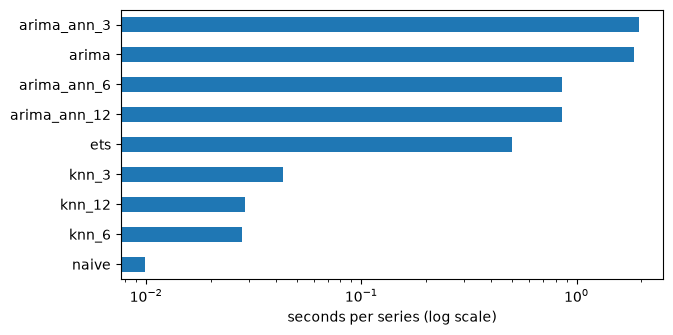

model
naive           0.010
knn_6           0.028
knn_12          0.029
knn_3           0.043
ets             0.501
arima_ann_12    0.860
arima_ann_6     0.860
arima           1.845
arima_ann_3     1.941
Name: seconds, dtype: float64

In [20]:
cost = final.groupby(["model", "series_id"]).seconds.sum().groupby("model").mean().sort_values()
ax = cost.plot.barh(figsize=(7, 3.5), log=True)
ax.set(xlabel="seconds per series (log scale)", ylabel="")
plt.show()
cost.round(3)

## 8. Reading

- **Classes.** The 17 series split into 8 stationary, 6 with lower seasonal strength and 3 with higher seasonal strength. The stationary ones are the hardest: the best RRMSE at `h = 12` is around 0.28–0.36, against 0.05–0.12 in the other two classes.
- **Protocol A (12 steps at once).** KNN wins on the lower seasonal strength series (`knn_6`, 0.088) and on the stationary ones (`knn_12`, 0.363); ETS wins on the higher seasonal strength series (0.118). Almost every model beats persistence on average; the exceptions are the hybrid in several windows and `knn_6` on the higher seasonal strength series.
- **Protocol B (one step at a time).** With each value revealed after its forecast, the statistical models take the lead: ARIMA on lower seasonal strength (0.047), ETS on higher seasonal strength (0.078) and on the stationary series (0.281). The one-step error is lower than in A for most models.
- **Horizon.** In protocol A, ARIMA is the best at the first step on the lower seasonal strength series (0.009), but the accumulated error grows to 0.135 at 12 steps and KNN overtakes it. ETS degrades little with the horizon.
- **Lags.** In protocol A, KNN with 12 lags is the best choice on the stationary and the higher seasonal strength series; on lower seasonal strength, 3, 6 and 12 are close. For the hybrid, the 12-residual window is usually the least bad.
- **ARIMA–ANN hybrid.** The corrector made ARIMA worse in every class, protocol and window: the median gain ranges from −0.5 % to −127 %. On the stationary series, in protocol A, the loss stays significant after Holm's correction (p between 0.02 and 0.05); in the other classes, with 3 to 6 series, the tests are inconclusive. A likely explanation is that the ARIMA residuals have little structure to learn, so the network ends up adding noise to the forecast.
- **Cost.** ARIMA is the most expensive model (about 1.8 s per series over both protocols); KNN and persistence cost hundredths of a second. The hybrid looks cheaper than its base because it reuses the cached ARIMA fit.
- **Limits.** There are few series per class, a single 12-point test and fixed hyperparameters, without search. To decide whether a hybrid is worth it for a series, use `compare_models`, which accepts the extra complexity only when it passes the validation criteria.